
# Lab 3: Supervised Machine Learning — Classification and Regression

**Course:** Artificial Intelligence Algorithms and Mathematics  
**Student Name:** Ubaid Ullah  
**Student ID:** 9110715  
**Section:** 1  

---

## 1. Introduction

This lab explores two supervised machine learning techniques to solve real-world prediction problems using Python and scikit-learn.

**Part A — Credit Card Fraud Detection**

The objective is to develop a Logistic Regression classification model that identifies potentially fraudulent credit card transactions. The model will be trained on 70% of the data and tested on the remaining 30%.

**Part B — Insurance Cost Prediction**

The objective is to develop a Linear Regression model that predicts individual medical insurance charges based on demographic and lifestyle characteristics. A 70/30 train-test split will also be applied.

## 2. Learning Objectives

By completing this lab, the following tasks will be demonstrated:

1. Load and explore real-world datasets using pandas.
2. Identify missing values, duplicates, and relevant data characteristics.
3. Perform appropriate preprocessing and exploratory data analysis (EDA).
4. Split each dataset into 70% training and 30% testing data.
5. Train Logistic Regression and Linear Regression models.
6. Evaluate model performance using suitable classification and regression metrics.
7. Visualize results and interpret the models' predictive performance.
8. Summarize key findings, limitations, and possible improvements.

## 3. Datasets

**Dataset A: Credit Card Fraud Detection**
- Source: Kaggle — Machine Learning Group, ULB
- File: `creditcard.csv`
- Target variable: `Class`
- Problem type: Binary Classification

**Dataset B: Medical Cost Personal Dataset**
- Source: Kaggle — Mirichoi
- File: `insurance.csv`
- Target variable: `charges`
- Problem type: Regression

Both datasets will be analyzed independently using the algorithms specified in the lab instructions.



## 4. Python Libraries and Environment Setup

This lab uses Python libraries for data manipulation, exploratory data analysis, visualization, and machine learning.

The main libraries include:

- **pandas:** Loading, cleaning, and analyzing datasets.
- **NumPy:** Numerical calculations and array operations.
- **Matplotlib:** Creating graphs and visualizations.
- **Seaborn:** Statistical visualizations and data exploration.
- **scikit-learn:** Data preprocessing, model training, and performance evaluation.

Additional scikit-learn components will be imported as needed for each prediction task.


In [1]:

# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Verify that the libraries are available
print("All required data analysis libraries imported successfully.")


All required data analysis libraries imported successfully.



---

## 5. Part A — Credit Card Fraud Detection

### 5.1 Dataset Loading and Initial Inspection

The Credit Card Fraud Detection dataset contains credit card transactions labeled as legitimate or fraudulent.

The target variable is `Class`:
- **0:** Legitimate transaction
- **1:** Fraudulent transaction

The dataset also contains `Time`, `Amount`, and anonymized numerical features (`V1` through `V28`).

In this section, the dataset is loaded using pandas, and its dimensions, column names, and first five records are examined to understand its structure before preprocessing.


In [2]:

# Load the credit card fraud dataset
creditcard_df = pd.read_csv("creditcard.csv")

# Display the dataset dimensions
print("Dataset Shape (Rows, Columns):", creditcard_df.shape)

# Display column names
print("\nColumn Names:")
print(creditcard_df.columns.tolist())

# Display the first five records
print("\nFirst Five Records:")
display(creditcard_df.head())


Dataset Shape (Rows, Columns): (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First Five Records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



### 5.2 Data Quality Assessment

Before training the classification model, the dataset is examined for potential data quality issues.

The following checks are performed:

1. **Data types:** Verify whether the features contain numerical or categorical values.
2. **Missing values:** Identify any incomplete records that may require treatment.
3. **Duplicate records:** Identify repeated transactions that could affect model evaluation.

These checks help determine which preprocessing steps are necessary. Any duplicate removal will be considered carefully because fraudulent transactions are rare.


In [3]:

# Examine dataset information and data types
print("Dataset Information:")
creditcard_df.info()

# Check missing values
print("\nMissing Values by Column:")
missing_values = creditcard_df.isnull().sum()
display(missing_values.to_frame(name="Missing Values"))

print("Total Missing Values:", missing_values.sum())

# Check duplicate records
duplicate_count = creditcard_df.duplicated().sum()
print("\nTotal Duplicate Records:", duplicate_count)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total Missing Values: 0

Total Duplicate Records: 1081



#### 5.2.1 Data Quality Findings

The initial data quality assessment produced the following findings:

- **Dataset size:** 284,807 transactions and 31 columns.
- **Data types:** 30 columns contain `float64` values, while the target variable `Class` contains `int64` values.
- **Missing values:** No missing values were detected in any column. Therefore, missing-value imputation is unnecessary.
- **Duplicate records:** 1,081 duplicate rows were identified, representing approximately 0.38% of the dataset.
- **Memory usage:** Approximately 67.4 MB.

**Interpretation:**

The dataset is suitable for further analysis because all features are numerical and there are no missing values. However, the presence of 1,081 duplicate records requires additional investigation.

Duplicate transactions will not be removed automatically because their distribution across legitimate and fraudulent classes must first be examined. This is particularly important for fraud detection, where fraudulent transactions are relatively rare.

The next step is to analyze the target variable distribution and investigate duplicate records by transaction class.



### 5.3 Class Distribution and Duplicate Analysis

Understanding the distribution of the target variable is essential for credit card fraud detection.

This analysis examines:

1. The number and percentage of legitimate and fraudulent transactions.
2. The distribution of duplicate records across both classes.

These findings will help determine whether class imbalance requires special consideration during model training and evaluation.


In [4]:

# Count transactions in each class
class_counts = creditcard_df["Class"].value_counts().sort_index()

# Calculate class percentages
class_percentages = (
    creditcard_df["Class"].value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Transaction Count": class_counts,
    "Percentage (%)": class_percentages.round(4)
})

class_distribution.index = ["Legitimate (0)", "Fraudulent (1)"]

print("Transaction Class Distribution:")
display(class_distribution)

# Investigate duplicate records by class
duplicate_mask = creditcard_df.duplicated()

print("\nDuplicate Records by Class:")
print(
    creditcard_df.loc[duplicate_mask, "Class"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

print("\nTotal Duplicate Records:", duplicate_mask.sum())


Transaction Class Distribution:


,Transaction Count,Percentage (%)
Legitimate (0),284315,99.8273
Fraudulent (1),492,0.1727



Duplicate Records by Class:
Class
Legitimate    1062
Fraudulent      19
Name: count, dtype: int64

Total Duplicate Records: 1081



#### 5.3.1 Class Distribution and Duplicate Analysis Findings

The dataset contains 284,807 credit card transactions, distributed as follows:

| Transaction Type | Count | Percentage |
|---|---:|---:|
| Legitimate (Class 0) | 284,315 | 99.8273% |
| Fraudulent (Class 1) | 492 | 0.1727% |

**Key Findings:**

1. **Severe Class Imbalance:** Only 0.1727% of transactions are fraudulent. Therefore, classification accuracy alone may be misleading. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy without detecting any fraud.

2. **Duplicate Records:** A total of 1,081 duplicate records were identified, including 1,062 legitimate and 19 fraudulent records.

3. **Preprocessing Decision:** Exact duplicate rows will be removed before splitting the dataset to reduce the possibility of identical observations appearing in both training and testing sets. However, because transaction identifiers are unavailable, we cannot confirm whether every identical row represents a repeated recording rather than a distinct transaction.

4. **Model Evaluation:** In addition to accuracy, precision, recall, F1-score, and the confusion matrix will be used to assess fraud detection performance.

5. **Train-Test Strategy:** A stratified 70/30 train-test split will be applied to preserve approximately the same fraud proportion in both datasets.

These decisions aim to provide a more reliable evaluation of the Logistic Regression classification model.


In [5]:

# Remove exact duplicate rows before train-test splitting
creditcard_clean_df = creditcard_df.drop_duplicates().copy()

# Compare the original and cleaned datasets
print("Original Dataset Shape:", creditcard_df.shape)
print("Cleaned Dataset Shape:", creditcard_clean_df.shape)

print("\nRecords Removed:",
      len(creditcard_df) - len(creditcard_clean_df))

# Verify that no duplicate rows remain
print("Remaining Duplicates:",
      creditcard_clean_df.duplicated().sum())

# Examine the class distribution after cleaning
print("\nClass Distribution After Cleaning:")
display(
    creditcard_clean_df["Class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .to_frame(name="Transaction Count")
)


Original Dataset Shape: (284807, 31)
Cleaned Dataset Shape: (283726, 31)

Records Removed: 1081
Remaining Duplicates: 0

Class Distribution After Cleaning:


,Transaction Count
Class,
Legitimate,283253
Fraudulent,473



### 5.4 Visualization of Class Distribution

The distribution of legitimate and fraudulent transactions is visualized using a bar chart.

Because the dataset is highly imbalanced, a logarithmic scale is applied to the vertical axis so that both classes remain visible.

The chart displays transaction counts and percentages to illustrate the difference between the majority and minority classes after duplicate removal.


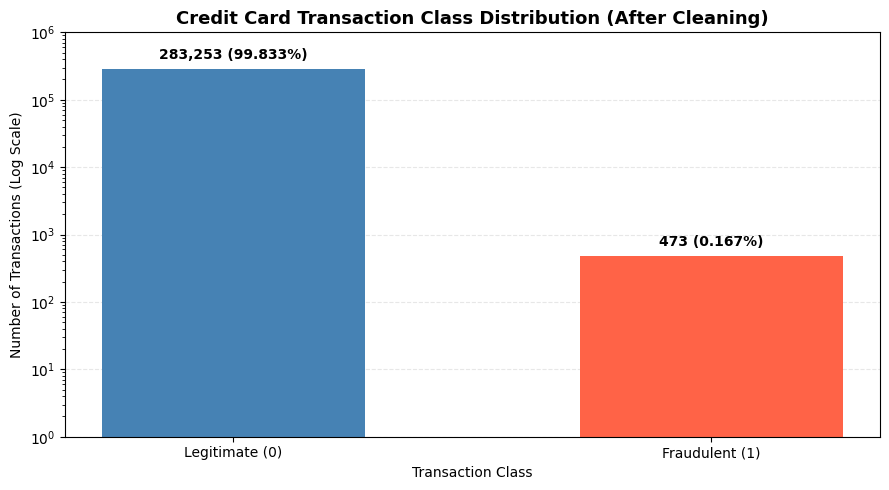

In [6]:

# Calculate class counts and percentages after cleaning
class_counts_clean = (
    creditcard_clean_df["Class"].value_counts().sort_index()
)

class_percentages_clean = (
    class_counts_clean / class_counts_clean.sum() * 100
)

# Define descriptive labels
class_labels = ["Legitimate (0)", "Fraudulent (1)"]

# Create the class distribution visualization
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_labels,
    class_counts_clean.values,
    color=["steelblue", "tomato"],
    width=0.55
)

# Use logarithmic scaling to highlight the minority class
ax.set_yscale("log")

# Add transaction counts and percentages above each bar
for bar, count, percentage in zip(
    bars, class_counts_clean.values, class_percentages_clean.values
):
    ax.annotate(
        f"{count:,} ({percentage:.3f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Add descriptive labels
ax.set_title(
    "Credit Card Transaction Class Distribution (After Cleaning)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions (Log Scale)")
ax.set_ylim(1, 1_000_000)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.4.1 Visualization Findings

The class distribution visualization confirms that legitimate transactions significantly outnumber fraudulent transactions.

After removing exact duplicates, the dataset contains 283,253 legitimate transactions and only 473 fraudulent transactions.

This severe class imbalance presents a challenge for Logistic Regression because a model may favor the majority class and still achieve high overall accuracy.

Therefore, the dataset will be divided using stratified sampling, and performance evaluation will include precision, recall, F1-score, and a confusion matrix in addition to accuracy.



### 5.5 Descriptive Statistics and Feature Analysis

Descriptive statistics help identify the central tendency, variability, and range of numerical features.

The dataset contains:
- **Time:** Seconds elapsed between each transaction and the first transaction in the dataset.
- **Amount:** Transaction amount.
- **V1–V28:** Anonymized numerical features obtained through Principal Component Analysis (PCA).
- **Class:** Binary target variable (0 = legitimate, 1 = fraudulent).

This analysis focuses on the `Time` and `Amount` features and compares transaction amounts across legitimate and fraudulent classes.

The results will help identify potential differences between transaction groups and inform preprocessing decisions.


In [7]:

# Descriptive statistics for Time and Amount
print("Descriptive Statistics for Time and Amount:")

display(
    creditcard_clean_df[["Time", "Amount"]]
    .describe()
    .T
    .round(2)
)

# Compare transaction amounts by class
print("\nTransaction Amount Statistics by Class:")

amount_by_class = (
    creditcard_clean_df
    .groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

amount_by_class.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

display(amount_by_class)

# Check transactions with zero amount
zero_amount_count = (
    creditcard_clean_df["Amount"] == 0
).sum()

print("\nTransactions with Zero Amount:", zero_amount_count)


Descriptive Statistics for Time and Amount:


,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.08,47481.05,0.0,54204.75,84692.5,139298.00,172792.00
Amount,283726.0,88.47,250.40,0.0,5.60,22.0,77.51,25691.16



Transaction Amount Statistics by Class:


,count,mean,median,std,min,max
Legitimate (0),283253,88.41,22.00,250.38,0.0,25691.16
Fraudulent (1),473,123.87,9.82,260.21,0.0,2125.87



Transactions with Zero Amount: 1808



#### 5.5.1 Descriptive Statistics Findings

The descriptive statistical analysis of the cleaned dataset revealed the following:

**1. Transaction Time**
- The average transaction time is 94,811.08 seconds.
- Transaction times range from 0 to 172,792 seconds.
- Time is measured relative to the first transaction rather than as a calendar date.

**2. Transaction Amount**
- The average transaction amount is 88.47.
- The median transaction amount is 22.00.
- Transaction amounts range from 0 to 25,691.16.
- The mean is substantially higher than the median, indicating a right-skewed distribution influenced by large transactions.

**3. Comparison Between Transaction Classes**

| Statistic | Legitimate | Fraudulent |
|---|---:|---:|
| Mean Amount | 88.41 | 123.87 |
| Median Amount | 22.00 | 9.82 |
| Standard Deviation | 250.38 | 260.21 |
| Maximum Amount | 25,691.16 | 2,125.87 |

Fraudulent transactions have a higher mean amount (123.87) but a lower median amount (9.82) compared with legitimate transactions.

This suggests that some larger fraudulent transactions increase the average, even though at least half of fraudulent transactions involve relatively small amounts.

**4. Zero-Amount Transactions**

A total of 1,808 transactions have an amount of zero. These records will be retained because a zero amount does not necessarily indicate invalid data.

**Preprocessing Implications**

The `Time` and `Amount` features have different numerical scales from the anonymized PCA features. Therefore, feature standardization will be considered during Logistic Regression preprocessing.

The large differences between the mean and median also suggest that transaction amounts are right-skewed. Visual analysis will help examine these distributions further.



### 5.6 Transaction Amount Distribution by Class

This analysis compares transaction amount distributions between legitimate and fraudulent transactions.

A logarithmic transformation, `log(1 + Amount)`, is used for visualization because the original amounts are highly right-skewed.

Each class histogram is normalized independently to allow a meaningful comparison despite the large difference in class sizes.

This transformation is applied only to the visualization and does not modify the original dataset.


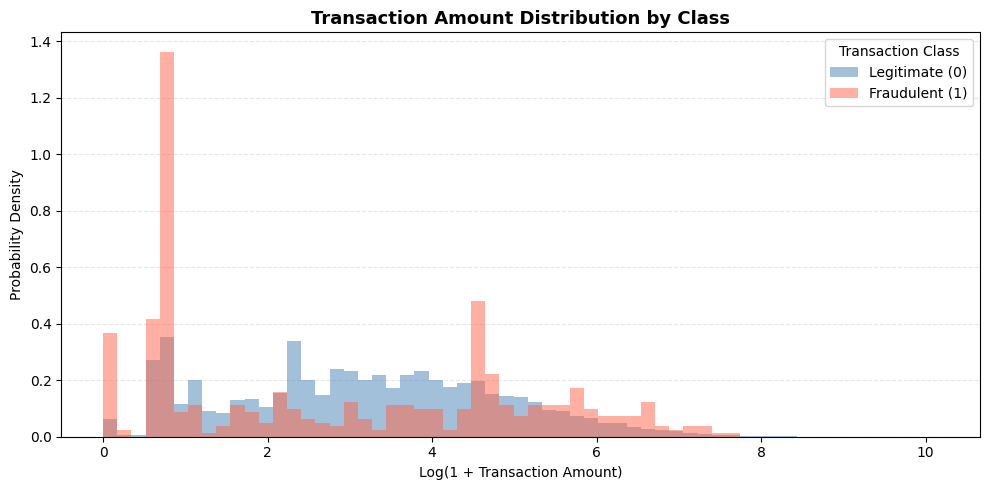

In [8]:

# Extract transaction amounts for each class
legitimate_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 0, "Amount"
]

fraudulent_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 1, "Amount"
]

# Apply log(1 + Amount) for visualization only
legitimate_log = np.log1p(legitimate_amounts)
fraudulent_log = np.log1p(fraudulent_amounts)

# Use common histogram bins for a fair comparison
bins = np.linspace(
    0,
    np.log1p(creditcard_clean_df["Amount"].max()),
    60
)

# Create normalized histograms
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    legitimate_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="steelblue",
    label="Legitimate (0)"
)

ax.hist(
    fraudulent_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="tomato",
    label="Fraudulent (1)"
)

# Format the visualization
ax.set_title(
    "Transaction Amount Distribution by Class",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Log(1 + Transaction Amount)")
ax.set_ylabel("Probability Density")
ax.legend(title="Transaction Class")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.6.1 Transaction Amount Distribution Findings

The normalized histograms reveal differences in transaction amount patterns between legitimate and fraudulent transactions.

**Key Observations:**

1. **Legitimate Transactions:** Transaction amounts are distributed across a relatively broad range, with several concentrations at different values.

2. **Fraudulent Transactions:** Fraudulent transactions show a strong concentration at smaller amounts and another noticeable peak around a log-transformed amount of 4.8.

3. **Overlapping Distributions:** Both classes overlap across several transaction amount ranges. This suggests that transaction amount alone may not provide sufficient information to distinguish fraudulent transactions reliably.

4. **Class Imbalance:** Normalizing each histogram independently allows the two distributions to be compared despite their substantially different sample sizes.

5. **Preprocessing:** The visualization demonstrates the skewness of transaction amounts. The logarithmic transformation was used only for exploratory visualization, while the original `Amount` values remain unchanged for subsequent preprocessing.

**Conclusion:**

Transaction amount provides useful descriptive information, but additional features are necessary for effective fraud classification. Logistic Regression will use the available numerical features to learn relationships associated with fraudulent transactions.



### 5.7 Correlation Analysis

Correlation analysis is used to investigate the relationships between numerical features and the target variable, `Class`.

Pearson correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear relationship.
- **-1:** Perfect negative linear relationship.
- **0:** No linear relationship.

Because `Class` is binary (0 or 1), its Pearson correlation with a numerical feature measures the direction and strength of their linear association.

The ten features with the largest absolute correlations with `Class` will be identified and visualized.

This analysis is exploratory only. Correlation does not establish causation or guarantee predictive importance, and features will not be selected based on these full-dataset correlations.


Top 10 Features Correlated with Fraud:


,Correlation with Class
V17,-0.3135
V14,-0.2934
V12,-0.2507
V10,-0.2070
V16,-0.1872
V3,-0.1823
V7,-0.1723
V11,0.1491
V4,0.1293
V18,-0.1053


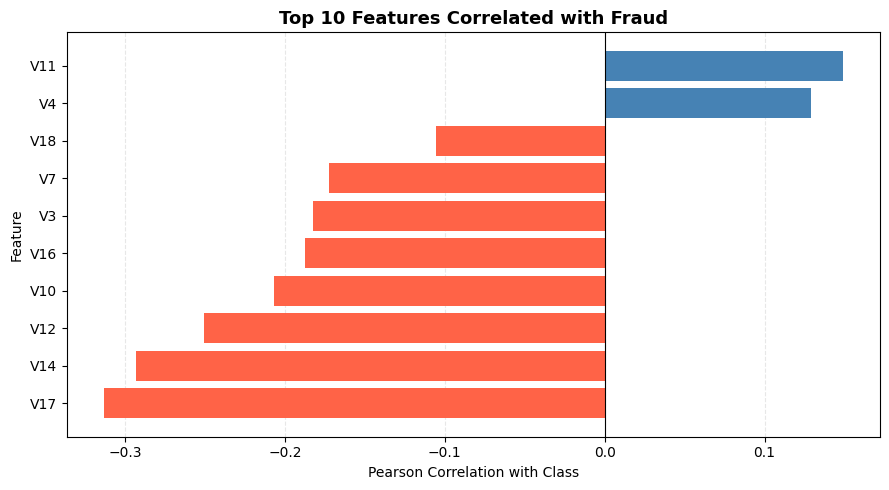

In [9]:

# Calculate Pearson correlations for numerical columns
correlation_matrix = creditcard_clean_df.corr(numeric_only=True)

# Extract correlations with the target variable
target_correlations = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

# Display the ten strongest absolute correlations
print("Top 10 Features Correlated with Fraud:")

display(
    target_correlations.head(10)
    .to_frame(name="Correlation with Class")
    .round(4)
)

# Visualize the top ten correlations
top_correlations = target_correlations.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    "steelblue" if value >= 0 else "tomato"
    for value in top_correlations.values
]

ax.barh(
    top_correlations.index,
    top_correlations.values,
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Top 10 Features Correlated with Fraud",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Pearson Correlation with Class")
ax.set_ylabel("Feature")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.7.1 Correlation Analysis Findings

The Pearson correlation analysis identified several anonymized numerical features associated with fraudulent transactions.

**Key Findings:**

1. **Strongest Negative Correlations:** V17 (-0.3135), V14 (-0.2934), and V12 (-0.2507) have the largest absolute correlations with the target variable. Their negative coefficients indicate that higher feature values tend to be associated with lower fraud occurrence.

2. **Positive Correlations:** V11 (0.1491) and V4 (0.1293) show positive associations with fraudulent transactions.

3. **Correlation Strength:** None of the individual features demonstrates a very strong linear relationship with fraud. However, multiple features may collectively provide useful predictive information.

4. **Feature Interpretation:** Since V1–V28 are anonymized PCA-derived features, their original business meanings are unavailable. Therefore, the observed correlations cannot be interpreted as direct causal relationships.

5. **Modeling Decision:** All 30 numerical predictors will be retained for the initial Logistic Regression model. The full-dataset correlation analysis is used only for descriptive exploration, not for feature selection or model tuning.

**Conclusion:**

The analysis suggests that several anonymized features contain information associated with fraudulent transactions. Logistic Regression will combine these predictors to estimate fraud probabilities.



### 5.8 Train-Test Split (70/30)

The cleaned dataset is divided into training and testing subsets using scikit-learn's `train_test_split()` function.

- **Training set (70%):** Used to train the Logistic Regression model.
- **Testing set (30%):** Reserved for evaluating model performance on unseen observations.
- **Stratified sampling:** Preserves approximately the same proportion of legitimate and fraudulent transactions in both subsets.
- **Random state (42):** Ensures that the split is reproducible.

The target variable `Class` is separated from the predictor features to prevent target leakage.

The test set will remain separate during model fitting and preprocessing.


In [10]:

from sklearn.model_selection import train_test_split

# Separate predictor features and target variable
X = creditcard_clean_df.drop(columns=["Class"])
y = creditcard_clean_df["Class"]

# Split into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

# Compare class distributions in both subsets
split_summary = pd.DataFrame({
    "Training Count": y_train.value_counts().reindex([0, 1]),
    "Testing Count": y_test.value_counts().reindex([0, 1]),
    "Training (%)": (
        y_train.value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ).round(4),
    "Testing (%)": (
        y_test.value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ).round(4)
})

split_summary.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

print("\nClass Distribution After Stratified Split:")
display(split_summary)


Training Features: (198608, 30)
Testing Features: (85118, 30)

Training Labels: (198608,)
Testing Labels: (85118,)

Class Distribution After Stratified Split:


,Training Count,Testing Count,Training (%),Testing (%)
Legitimate (0),198277,84976,99.8333,99.8332
Fraudulent (1),331,142,0.1667,0.1668



#### 5.8.1 Train-Test Split Findings

The cleaned dataset was successfully divided into 70% training data and 30% testing data using stratified sampling.

| Transaction Class | Training | Testing |
|---|---:|---:|
| Legitimate (0) | 198,277 | 84,976 |
| Fraudulent (1) | 331 | 142 |
| **Total** | **198,608** | **85,118** |

**Key Findings:**

1. The training dataset contains 198,608 transactions, while the testing dataset contains 85,118 transactions.
2. The fraudulent transaction proportion is approximately 0.167% in both subsets.
3. Stratification successfully preserved the original class imbalance.
4. The training set will be used to fit the model, while the testing set will be reserved for final evaluation.

**Conclusion:**

The stratified 70/30 split provides representative training and testing subsets while maintaining the naturally imbalanced distribution of fraudulent transactions.



### 5.9 Feature Standardization

Logistic Regression is sensitive to differences in feature scales, particularly when regularization is applied.

The dataset contains features with substantially different numerical ranges. For example, `Time` contains values up to 172,792, while the anonymized PCA features have different distributions.

To address these differences, `StandardScaler` is applied to standardize all 30 predictor features.

Standardization uses the following formula:

$$
z = \frac{x - \mu}{\sigma}
$$

Where:
- $x$ represents the original feature value.
- $\mu$ represents the training feature mean.
- $\sigma$ represents the training feature standard deviation.

**Data Leakage Prevention:**

The scaler is fitted exclusively on the training data using `fit_transform()`. The testing data is then standardized using `transform()` without recalculating the scaling parameters.

This ensures that information from the test set does not influence the preprocessing learned from training data.

The target variable `Class` is not standardized.


In [11]:

from sklearn.preprocessing import StandardScaler

# Initialize the feature scaler
scaler = StandardScaler()

# Fit the scaler only on training data
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply training-derived scaling to testing data
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify standardized dataset dimensions
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# Compare original and standardized feature statistics
features_to_check = ["Time", "Amount", "V17"]

scaling_comparison = pd.DataFrame({
    "Original Mean": X_train[features_to_check].mean(),
    "Original Std": X_train[features_to_check].std(ddof=0),
    "Scaled Mean": X_train_scaled[features_to_check].mean(),
    "Scaled Std": X_train_scaled[features_to_check].std(ddof=0)
})

print("\nFeature Standardization Verification:")
display(scaling_comparison.round(4))

# Check for missing values introduced during scaling
print(
    "\nMissing Values After Scaling:",
    X_train_scaled.isna().sum().sum()
    + X_test_scaled.isna().sum().sum()
)


Scaled Training Shape: (198608, 30)
Scaled Testing Shape: (85118, 30)

Feature Standardization Verification:


,Original Mean,Original Std,Scaled Mean,Scaled Std
Time,94915.8742,47485.4083,-0.0,1.0
Amount,88.3217,242.6128,0.0,1.0
V17,-0.0011,0.8426,-0.0,1.0



Missing Values After Scaling: 0



#### 5.9.1 Feature Standardization Findings

The StandardScaler preprocessing was successfully applied to all 30 predictor features.

**Key Findings:**

1. The training dataset contains 198,608 transactions, and the testing dataset contains 85,118 transactions.
2. The standardized training features have means approximately equal to 0 and standard deviations equal to 1.
3. No missing values were introduced during preprocessing.
4. Scaling parameters were calculated exclusively from the training dataset to prevent data leakage.
5. The original binary target variable, `Class`, remained unchanged.

**Conclusion:**

The numerical features are now standardized and ready for Logistic Regression training.

### 5.10 Logistic Regression Model Training

Logistic Regression is a supervised classification algorithm used to estimate the probability that a transaction belongs to a particular class.

In this lab:
- **Class 0:** Legitimate transaction.
- **Class 1:** Fraudulent transaction.

The model uses the standardized training features to learn relationships between transaction characteristics and fraud occurrence.

**Initial Model Configuration:**

- **Algorithm:** Logistic Regression
- **Solver:** `lbfgs`
- **Maximum iterations:** 1000
- **Class weighting:** None (baseline model)
- **Random state:** 42

The baseline model will be evaluated using the independent test dataset. Because fraudulent transactions are rare, its performance will be assessed using metrics beyond accuracy.

A class-weighted Logistic Regression model may also be compared to investigate how addressing class imbalance affects fraud detection.


In [12]:

from sklearn.linear_model import LogisticRegression

# Initialize the baseline Logistic Regression model
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Train using only the standardized training dataset
logistic_model.fit(X_train_scaled, y_train)

# Verify successful model training
print("Logistic Regression Model Trained Successfully!")

print("\nModel Configuration:")
print("Algorithm: Logistic Regression")
print("Solver:", logistic_model.solver)
print("Maximum Iterations:", logistic_model.max_iter)
print("Actual Iterations:", logistic_model.n_iter_[0])
print("Number of Features:", logistic_model.n_features_in_)
print("Classes:", logistic_model.classes_)


Logistic Regression Model Trained Successfully!

Model Configuration:
Algorithm: Logistic Regression
Solver: lbfgs
Maximum Iterations: 1000
Actual Iterations: 16
Number of Features: 30
Classes: [0 1]



#### 5.10.1 Model Training Findings

The baseline Logistic Regression model was trained successfully using 198,608 standardized training observations and 30 predictor features.

The `lbfgs` solver completed optimization in 16 iterations, below the configured maximum of 1,000 iterations. No convergence warning was reported.

The model recognizes two classes:
- **0:** Legitimate transactions.
- **1:** Fraudulent transactions.

The next step is to evaluate the model using the independent 30% testing dataset.

### 5.11 Baseline Model Evaluation

The trained Logistic Regression model will be evaluated using the testing dataset, which was not used during model training.

The following evaluation metrics are considered:

1. **Accuracy:** Proportion of all correctly classified transactions.
2. **Precision:** Proportion of predicted fraudulent transactions that are actually fraudulent.
3. **Recall:** Proportion of actual fraudulent transactions correctly detected.
4. **F1-Score:** Harmonic mean of precision and recall.
5. **Confusion Matrix:** Counts of true negatives, false positives, false negatives, and true positives.
6. **ROC-AUC:** Measures how well the model ranks fraudulent transactions above legitimate transactions across classification thresholds.
7. **Average Precision (AP):** Summarizes precision-recall performance across thresholds, which is especially useful for imbalanced classification.

A default probability threshold of 0.50 is used for the baseline classification predictions.

Because only approximately 0.167% of test transactions are fraudulent, accuracy alone is insufficient for evaluating fraud detection performance. A majority-class baseline will also be calculated for comparison.


In [13]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Predict transaction classes using the trained model
y_pred = logistic_model.predict(X_test_scaled)

# Obtain probabilities for the fraudulent class (Class 1)
y_pred_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Calculate classification performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Calculate probability-based evaluation metrics
roc_auc = roc_auc_score(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

# Calculate majority-class baseline accuracy
majority_baseline_accuracy = (y_test == 0).mean()

# Display model performance
print("Baseline Logistic Regression Performance")
print("-" * 45)

print(f"Accuracy:          {accuracy:.6f}")
print(f"Precision:         {precision:.6f}")
print(f"Recall:            {recall:.6f}")
print(f"F1-Score:          {f1:.6f}")
print(f"ROC-AUC:           {roc_auc:.6f}")
print(f"Average Precision: {average_precision:.6f}")

print(
    f"\nMajority-Class Baseline Accuracy: "
    f"{majority_baseline_accuracy:.6f}"
)

# Display detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate (0)", "Fraudulent (1)"],
        zero_division=0
    )
)

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Extract confusion matrix components
tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix Breakdown:")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")


Baseline Logistic Regression Performance
---------------------------------------------
Accuracy:          0.999084
Precision:         0.840426
Recall:            0.556338
F1-Score:          0.669492
ROC-AUC:           0.964678
Average Precision: 0.704037

Majority-Class Baseline Accuracy: 0.998332

Classification Report:
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00     84976
Fraudulent (1)       0.84      0.56      0.67       142

      accuracy                           1.00     85118
     macro avg       0.92      0.78      0.83     85118
  weighted avg       1.00      1.00      1.00     85118

Confusion Matrix:
[[84961    15]
 [   63    79]]

Confusion Matrix Breakdown:
True Negatives  (TN): 84961
False Positives (FP): 15
False Negatives (FN): 63
True Positives  (TP): 79



#### 5.11.1 Baseline Logistic Regression Evaluation Findings

The baseline Logistic Regression model was evaluated on 85,118 unseen test transactions.

**Performance Results:**

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 99.91% |
| Precision (Fraud) | 84.04% |
| Recall (Fraud) | 55.63% |
| F1-Score (Fraud) | 66.95% |
| ROC-AUC | 0.9647 |
| Average Precision | 0.7040 |
| Majority-Class Baseline Accuracy | 99.83% |

**Key Findings:**

1. **Accuracy:** The model correctly classified approximately 99.91% of all test transactions. This exceeds the majority-class baseline accuracy of 99.83%.

2. **Precision:** Of all transactions predicted as fraudulent, approximately 84.04% were actually fraudulent. Therefore, most fraud alerts generated by the model were correct.

3. **Recall:** The model identified only 55.63% of actual fraudulent transactions, meaning approximately 44.37% of fraudulent transactions were missed.

4. **F1-Score:** The fraud-class F1-score of 66.95% reflects the balance between precision and recall at the default classification threshold.

5. **ROC-AUC:** The ROC-AUC of 0.9647 indicates strong discrimination between legitimate and fraudulent transactions across classification thresholds.

6. **Average Precision:** The average precision of 0.7040 indicates useful precision-recall performance in this highly imbalanced classification problem.

**Confusion Matrix Interpretation:**

- **True Negatives (TN):** 84,961 legitimate transactions correctly classified.
- **False Positives (FP):** 15 legitimate transactions incorrectly flagged as fraudulent.
- **False Negatives (FN):** 63 fraudulent transactions incorrectly classified as legitimate.
- **True Positives (TP):** 79 fraudulent transactions correctly detected.

**Conclusion:**

Although the baseline model achieves excellent overall accuracy and relatively high fraud precision, its recall remains limited.

The model successfully detected 79 of 142 fraudulent transactions but missed 63. These false negatives are important because undetected fraud may lead to financial losses.

Therefore, additional analysis of class imbalance and the precision-recall trade-off is necessary before considering this model suitable for practical fraud detection.



### 5.12 Confusion Matrix Visualization

A confusion matrix provides a detailed breakdown of the Logistic Regression model's predictions.

The matrix compares actual transaction classes with predicted transaction classes, identifying:

- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

Because the test dataset is highly imbalanced, the heatmap is normalized by actual class to make the minority-class performance visible.

Each cell displays both the original transaction count and its percentage within the corresponding actual class.


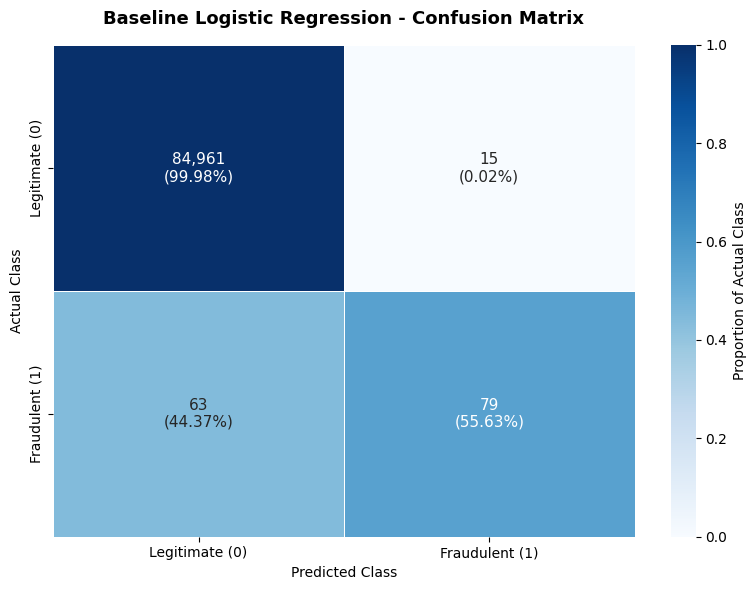

In [14]:

# Normalize the confusion matrix by actual class
cm_normalized = cm / cm.sum(axis=1, keepdims=True)

# Create annotations containing counts and percentages
cm_annotations = np.array([
    [
        f"{cm[i, j]:,}\n({cm_normalized[i, j]:.2%})"
        for j in range(cm.shape[1])
    ]
    for i in range(cm.shape[0])
])

# Create the normalized confusion matrix heatmap
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=cm_annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    xticklabels=["Legitimate (0)", "Fraudulent (1)"],
    yticklabels=["Legitimate (0)", "Fraudulent (1)"],
    cbar_kws={"label": "Proportion of Actual Class"},
    annot_kws={"fontsize": 11},
    ax=ax
)

# Add descriptive title and axis labels
ax.set_title(
    "Baseline Logistic Regression - Confusion Matrix",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()



#### 5.12.1 Confusion Matrix Findings

The normalized confusion matrix provides a detailed evaluation of the baseline Logistic Regression model on 85,118 test transactions.

**Key Findings:**

1. **True Negatives (84,961):** The model correctly identified 99.98% of legitimate transactions.

2. **False Positives (15):** Only 0.02% of legitimate transactions were incorrectly flagged as fraudulent, indicating a low false-positive rate.

3. **False Negatives (63):** The model incorrectly classified 44.37% of actual fraudulent transactions as legitimate.

4. **True Positives (79):** The model successfully detected 55.63% of fraudulent transactions.

**Interpretation:**

The model performs exceptionally well at identifying legitimate transactions while generating relatively few false fraud alerts.

However, its fraud detection recall is considerably lower. Of the 142 actual fraudulent transactions in the test dataset, 63 were missed.

This result demonstrates why the model's 99.91% overall accuracy does not fully represent its effectiveness in fraud detection.

**Conclusion:**

The baseline Logistic Regression model achieves high precision but moderate fraud recall at the default classification threshold of 0.50.

A practical fraud detection system must carefully balance the consequences of missed fraudulent transactions against incorrectly flagged legitimate transactions.

Further analysis will investigate the precision-recall relationship and explore whether class-weighted Logistic Regression can improve fraud detection without introducing excessive false positives.



### 5.13 Precision-Recall Curve Analysis

The Precision-Recall (PR) curve evaluates the relationship between precision and recall across different classification thresholds.

- **Precision:** Measures how many predicted fraudulent transactions are actually fraudulent.
- **Recall:** Measures how many actual fraudulent transactions are successfully detected.

Lowering the classification threshold may identify additional fraudulent transactions, but it can also increase false-positive predictions.

The Average Precision (AP) score summarizes the model's precision-recall performance across thresholds.

The proportion of fraudulent transactions in the testing dataset is used as a reference baseline.

This analysis is intended to explain the model's classification performance, not to select a threshold using the test dataset.


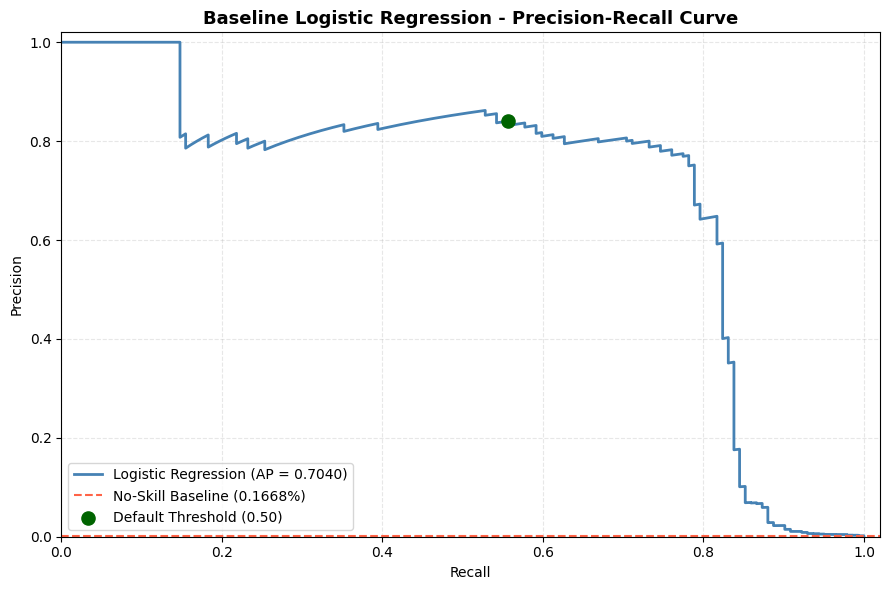

Average Precision: 0.7040
Fraud Prevalence: 0.1668%
Precision at Threshold 0.50: 84.0426%
Recall at Threshold 0.50: 55.6338%


In [15]:

from sklearn.metrics import precision_recall_curve

# Calculate precision and recall at different thresholds
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_pred_proba
)

# Calculate the positive-class prevalence
fraud_prevalence = y_test.mean()

# Create the Precision-Recall curve
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    pr_recall,
    pr_precision,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AP = {average_precision:.4f})"
)

# Add the no-skill reference baseline
ax.axhline(
    y=fraud_prevalence,
    color="tomato",
    linestyle="--",
    linewidth=1.5,
    label=f"No-Skill Baseline ({fraud_prevalence:.4%})"
)

# Highlight the default 0.50 threshold performance
ax.scatter(
    recall,
    precision,
    color="darkgreen",
    s=90,
    zorder=5,
    label="Default Threshold (0.50)"
)

# Format the visualization
ax.set_title(
    "Baseline Logistic Regression - Precision-Recall Curve",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower left")
ax.grid(linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Display summary results
print(f"Average Precision: {average_precision:.4f}")
print(f"Fraud Prevalence: {fraud_prevalence:.4%}")
print(f"Precision at Threshold 0.50: {precision:.4%}")
print(f"Recall at Threshold 0.50: {recall:.4%}")



#### 5.13.1 Precision-Recall Curve Findings

The Precision-Recall curve evaluates how the baseline Logistic Regression model performs at different classification thresholds.

**Key Findings:**

1. **Average Precision:** The model achieved an Average Precision (AP) score of 0.7040, indicating useful precision-recall performance across different classification thresholds.

2. **Class Imbalance:** The no-skill baseline is approximately 0.1668%, reflecting the extremely low proportion of fraudulent transactions in the test dataset. The model performs substantially better than this reference.

3. **Default Threshold (0.50):** At the default classification threshold, the model achieved 84.04% precision and 55.63% recall.

4. **Precision-Recall Trade-off:** The curve shows that precision generally decreases when attempting to detect a greater proportion of fraudulent transactions. This decline becomes particularly noticeable at higher recall levels.

5. **Model Limitations:** Although the model demonstrates strong overall accuracy and useful fraud detection capabilities, it still misses approximately 44.37% of actual fraudulent transactions at the default threshold.

**Conclusion:**

The Precision-Recall curve confirms that the baseline Logistic Regression model performs substantially better than random ranking but does not detect every fraudulent transaction.

Improving fraud recall may require accepting additional false-positive predictions.

The next analysis will investigate class-weighted Logistic Regression using a separate validation subset drawn exclusively from the training data. This avoids using the held-out test dataset to select model settings.



### 5.14 Class-Weighted Logistic Regression Comparison

The baseline Logistic Regression model achieved high overall accuracy but detected only 55.63% of fraudulent transactions at the default classification threshold.

To investigate this limitation, two Logistic Regression configurations will be compared:

1. **Standard Logistic Regression:** Uses the default class weighting.
2. **Balanced Logistic Regression:** Uses `class_weight="balanced"` to assign greater importance to the minority class.

#### Validation Strategy

To avoid selecting model settings based on test-set performance, the original 70% training subset is further divided into:

- **80% development data:** Used to fit the comparison models.
- **20% validation data:** Used to compare their performance.

Stratified sampling preserves the class proportions.

A scikit-learn Pipeline combines StandardScaler and Logistic Regression, ensuring that scaling parameters are learned only from the development data.

Both models use the same validation observations and the default classification threshold of 0.50 for a fair initial comparison.

The original 30% test dataset remains unchanged and will not be used to select the preferred configuration.


In [16]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Create a validation split using training data only
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Development Set:", X_dev.shape)
print("Validation Set:", X_val.shape)

# Define two Logistic Regression configurations
model_configs = {
    "Standard Logistic Regression": None,
    "Balanced Logistic Regression": "balanced"
}

validation_results = []

for model_name, class_weight in model_configs.items():

    # Build a leakage-safe preprocessing and model pipeline
    model_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight=class_weight,
            random_state=42
        ))
    ])

    # Fit only on development data
    model_pipeline.fit(X_dev, y_dev)

    # Predict using the independent validation subset
    val_predictions = model_pipeline.predict(X_val)
    val_probabilities = model_pipeline.predict_proba(X_val)[:, 1]

    # Extract confusion matrix components
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    ).ravel()

    # Collect validation performance
    validation_results.append({
        "Model": model_name,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, val_probabilities
        ),
        "False Positives": fp_val,
        "False Negatives": fn_val
    })

# Display the model comparison
validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.set_index("Model")

print("\nTraining-Only Validation Comparison:")
display(validation_comparison.round(4))


Development Set: (158886, 30)
Validation Set: (39722, 30)

Training-Only Validation Comparison:


,Precision,Recall,F1-Score,Average Precision,False Positives,False Negatives
Model,,,,,,
Standard Logistic Regression,0.8667,0.5909,0.7027,0.7363,6,27
Balanced Logistic Regression,0.0550,0.8939,0.1036,0.7100,1014,7



#### 5.14.1 Class-Weighted Model Comparison Findings

The two Logistic Regression configurations were evaluated using a stratified validation subset containing 39,722 transactions, drawn exclusively from the original training data.

**Key Findings:**

1. **Standard Logistic Regression:** Achieved 86.67% precision, 59.09% recall, and a 70.27% F1-score. It generated only 6 false positives but missed 27 fraudulent transactions.

2. **Balanced Logistic Regression:** Achieved higher recall (89.39%), reducing missed fraud cases to 7. However, precision decreased to 5.50%, with 1,014 false positives.

3. **Precision-Recall Trade-off:** Class weighting increased the model's sensitivity to fraud but substantially increased the number of legitimate transactions incorrectly flagged as fraudulent.

4. **Average Precision:** The standard model achieved an AP score of 0.7363, compared with 0.7100 for the balanced model. This indicates slightly better precision-recall ranking performance for the standard configuration on this validation subset.

5. **Model Selection:** The standard Logistic Regression configuration is preferred based on its higher validation F1-score and substantially lower false-positive count. F1-score is used as the primary selection criterion for this comparison.

**Limitations:**

The comparison uses a single validation split, and only a small number of fraudulent examples are available. Consequently, the estimated performance may vary with different samples.

The baseline test results were also inspected earlier in the exploratory workflow. Therefore, further model decisions will rely on training-only validation results rather than additional test-set experimentation.

**Conclusion:**

Class weighting improves fraud recall but introduces a considerable false-positive burden at the default threshold of 0.50.

For this lab, the standard Logistic Regression configuration provides a more balanced precision-recall trade-off according to the validation F1-score.

In a real-world fraud detection system, the preferred configuration would also depend on the financial costs of missed fraud and false alarms.


In [17]:

# Select the configuration with the highest validation F1-score
selected_model_name = validation_comparison["F1-Score"].idxmax()

print("Selected Model:", selected_model_name)
print("Selection Criterion: Highest Validation F1-Score")

print(
    "Validation F1-Score:",
    f"{validation_comparison.loc[selected_model_name, 'F1-Score']:.4f}"
)

print(
    "Validation Average Precision:",
    f"{validation_comparison.loc[selected_model_name, 'Average Precision']:.4f}"
)


Selected Model: Standard Logistic Regression
Selection Criterion: Highest Validation F1-Score
Validation F1-Score: 0.7027
Validation Average Precision: 0.7363



### 5.15 Part A — Final Conclusion

This part of the lab successfully developed and evaluated a Logistic Regression model for credit card fraud detection.

**Data Preparation and Analysis:**

- The original dataset contained 284,807 transactions.
- After removing 1,081 exact duplicate records, 283,726 transactions remained.
- No missing values were identified.
- Only 473 transactions (approximately 0.167%) were fraudulent, demonstrating severe class imbalance.
- A stratified 70/30 train-test split was applied.
- StandardScaler was fitted exclusively on training data to prevent preprocessing leakage.

**Baseline Model Performance:**

| Metric | Test Result |
|---|---:|
| Accuracy | 99.91% |
| Fraud Precision | 84.04% |
| Fraud Recall | 55.63% |
| Fraud F1-Score | 66.95% |
| ROC-AUC | 0.9647 |
| Average Precision | 0.7040 |

The baseline model correctly detected 79 of 142 fraudulent test transactions, while 63 fraudulent transactions were missed. Only 15 legitimate transactions were incorrectly flagged as fraudulent.

**Class-Weighting Comparison:**

A separate validation subset was used to compare standard and balanced Logistic Regression configurations.

The balanced model improved validation fraud recall from 59.09% to 89.39%. However, false positives increased from 6 to 1,014, and precision decreased considerably.

The standard Logistic Regression configuration was selected based on its higher validation F1-score (0.7027 versus 0.1036). The final test results reported above correspond to this configuration trained on the full original training subset.

**Limitations:**

- Severe class imbalance makes overall accuracy misleading.
- The baseline model misses a substantial proportion of fraudulent transactions.
- Exact duplicate removal may also remove distinct transactions with identical recorded features.
- The validation comparison relies on a single stratified split.
- Test performance was inspected earlier in the notebook; model selection subsequently relied on training-only validation results, but a completely untouched final test evaluation would provide stronger methodological assurance.

**Overall Conclusion:**

Logistic Regression provides a useful baseline for credit card fraud detection, achieving high precision and strong ROC-AUC performance.

However, the model's moderate fraud recall indicates that further development would be necessary before practical deployment.

The results highlight the importance of appropriate preprocessing, stratified sampling, multiple evaluation metrics, and careful consideration of the precision-recall trade-off when working with imbalanced datasets.
